In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

IMPORTING!!!

In [30]:
health = pd.read_stata('dataset/sharew6_rel9-0-0_gv_health.dta')
ph = pd.read_stata('dataset/sharew6_rel9-0-0_ph.dta')
dbs = pd.read_stata('dataset/sharew6_rel1-1-0_dbs.dta')
cv_r = pd.read_stata('dataset/sharew6_rel9-0-0_cv_r.dta')
br = pd.read_stata('dataset/sharew6_rel9-0-0_br.dta')

**PHYSICAL DATASET**

In [31]:
ph1 = ph.copy()
ph1 = ph.loc[:,['mergeid', 'ph006d1', 'ph006d4', 'ph006d5','ph006d10','ph011d2',
                'ph011d9','ph011d13','ph011d15','ph011dot']]
ph1 = ph1.rename(columns= {
    'ph006d1' : 'heart_attack',
    'ph006d4' : 'stroke', #ictus
    'ph006d5': 'diabetes',
    'ph006d10' : 'cancer',
    ###### DRUGS
    'ph011d2' : 'drug_hbp', #high blood pressure
    'ph011d9' : 'drug_sleep', #sleep drug
    'ph011d13' : 'drug_stom', #stomach
    'ph011d15' : 'drug_inf', #inflammation
    'ph011dot' : 'drug_oth'
})

ph1_col = ['heart_attack','stroke','diabetes','cancer',
                  'drug_hbp','drug_sleep','drug_stom','drug_inf','drug_oth']
ph1[ph1_col] = ph1[ph1_col].astype('object')

In [32]:
ph1[ph1_col] = ph1[ph1_col].replace({'Not selected': 0, 'Selected': 1})
ph1[ph1_col].agg(['value_counts'])
#refusal and 'Don't know are a small quantities, so i converted them in NA values

for col in [ph1_col]:
    ph1[col] = ph1[col].replace(['Refusal', "Don't know"], np.nan)
#transformation in NA ->. 156 NA

**HEALTH DATASET**

In [33]:
hh = health.copy()
hh = hh.loc[:,['mergeid', 'bmi', 'euro1','euro8','euro10','euro9','maxgrip', 'phactiv']]
hh = hh.rename(columns= {
    'euro1' : 'depr',
    'euro9' : 'fatigue',
    'euro8' : 'appetite',
    'euro10' : 'concen'
    })



hh_sub_col = ['depr', 'fatigue','appetite','concen']
hh_cat_col = ['depr', 'fatigue','appetite','concen','phactiv']


hh[hh_sub_col] = hh[hh_sub_col].astype('object')
hh['phactiv'] = hh['phactiv'].astype('object')


hh[hh_sub_col] = hh[hh_sub_col].replace({'Not selected': 0, 'Selected': 1})
hh['phactiv'] = hh['phactiv'].replace({'Other': 1,
                                       'Never vigorous nor moderate physical activity': 0})


In [34]:
#using the inactivity as activity
for col in hh_cat_col:
  print(hh[col].value_counts())

for col in hh_cat_col:
    hh[col] = hh[col].replace(['Refusal', "Don't know"], np.nan)
hh['phactiv'].isna().sum() #166 NA

depr
0             38721
1             26263
Refusal          21
Don't know       20
Name: count, dtype: int64
fatigue
0             41251
1             23712
Don't know       48
Refusal          11
Name: count, dtype: int64
appetite
0             58986
1              6020
Don't know       10
Refusal           6
Name: count, dtype: int64
concen
0             53610
1             11278
Don't know       16
Refusal           8
Name: count, dtype: int64
phactiv
1             59508
0              8381
Don't know       27
Refusal          18
Name: count, dtype: int64


np.int64(166)

**COVERSCREEN**

In [35]:
cv = cv_r.copy()
cv = cv.loc[:,['mergeid','age2015','gender']]
cv = cv.rename(columns= {'age2015' : 'age'})

cv['gender'] = cv['gender'].astype('object')
cv['gender'] = cv['gender'].replace({'Male': 1,
                                    'Female': 0})

cv.isna().sum()

mergeid      0
age        263
gender       0
dtype: int64

**DRAIN BLOOD SAMPLES**

In [36]:
dbs1 = dbs.copy()
dbs1 = dbs1.loc[:,['mergeid','cho_x4','crp_x4',
                   'trg_x4','cyc_x4','hdl_x4','thb_x4','a1c_x4',
                   'astar']]
# female column in dbs contains NAn values instead of gender. So for this reason
# we will use gender

dbs1 = dbs1.rename(columns={
    'cho_x4' : 'chol',
    'crp_x4' : 'crp',
    'trg_x4' : 'trigl',
    'cyc_x4' : 'cyst_c',
    'hdl_x4' : 'hdl',
    'thb_x4' : 'thb',
    'a1c_x4' : 'a1c'
})

**BEHAVIOURAL RISKS**

In [37]:
br1 = br.copy()
br1 = br1.loc[:,['mergeid', 'br001_', 'br039_']]

br1 = br1.rename(columns={
    'br001_' : 'smoke',
    'br039_' : 'alcohol'
})
br_col = ['smoke', 'alcohol']

br1[br_col]=br1[br_col].astype('object')

br1[br_col] = br1[br_col].replace({'No': 0, 'Yes': 1})
for col in br_col:
  br1[col] = br1[col].replace(['Refusal', "Don't know"], np.nan)

br1['alcohol'].value_counts()

alcohol
1    35417
0    32482
Name: count, dtype: int64

**MERGING**

In [38]:
df_merg = hh.merge(ph1, on='mergeid')\
        .merge(br1, on='mergeid')\
        .merge(cv, on='mergeid')\
        .merge(dbs1, on='mergeid')

In [39]:
df_sub = df_merg.copy()
df_sub = df_sub.dropna(subset=['chol'])

In [40]:
cat_tot = ['depr','appetite','concen','fatigue','phactiv',
           'drug_hbp','drug_stom','drug_sleep','drug_inf','drug_oth','alcohol','gender','astar']

num_tot = ['bmi','maxgrip','age','chol','crp','trigl','cyst_c','hdl','thb','a1c']

**MULTIPLE IMPUTATION:**

In [41]:
df_m = df_sub.copy()
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

biomarks = ['chol','crp','trigl','cyst_c','hdl','thb','a1c']

imputed_datasets = []

for seed in range(5):
    imp = IterativeImputer(max_iter=20, random_state=seed, sample_posterior=True)
    df_tmp = df_m.copy()
    df_tmp[biomarks] = imp.fit_transform(df_tmp[biomarks])
    imputed_datasets.append(df_tmp)

stacked = np.stack([df[biomarks].values for df in imputed_datasets], axis=0)
mean_values = stacked.mean(axis=0)

df_imp = df_m.copy()
df_imp[biomarks] = mean_values

In [ ]:
df_imp ['age'] = df_imp ['age'].astype(str)
df_imp ['age'] = pd.to_numeric(df_imp ['age'], errors='coerce')

df_imp ['maxgrip'] = df_imp ['maxgrip'].astype(str)
df_imp ['maxgrip'] = pd.to_numeric(df_imp ['maxgrip'], errors='coerce')

df_imp ['bmi'] = df_imp ['bmi'].astype(str)
df_imp ['bmi'] = pd.to_numeric(df_imp ['bmi'], errors='coerce')

df_imp.isna().sum()

In [45]:
df_imp.groupby(["gender"])[["bmi", "maxgrip"]].skew()

df_imp["bmi"] = df_imp.groupby("gender")["bmi"]\
                      .transform(lambda x: x.fillna(x.median()))

df_imp["maxgrip"] = df_imp.groupby("gender")["maxgrip"]\
                      .transform(lambda x: x.fillna(x.mean()))
df_imp.info()

<class 'pandas.DataFrame'>
Index: 23057 entries, 0 to 52328
Data columns (total 29 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mergeid       23057 non-null  str    
 1   bmi           23057 non-null  float64
 2   depr          22980 non-null  object 
 3   appetite      22985 non-null  object 
 4   concen        22957 non-null  object 
 5   fatigue       22975 non-null  object 
 6   maxgrip       23057 non-null  float64
 7   phactiv       23048 non-null  object 
 8   heart_attack  23054 non-null  object 
 9   stroke        23054 non-null  object 
 10  diabetes      23054 non-null  object 
 11  cancer        23054 non-null  object 
 12  drug_hbp      23042 non-null  object 
 13  drug_sleep    23042 non-null  object 
 14  drug_stom     23042 non-null  object 
 15  drug_inf      23042 non-null  object 
 16  drug_oth      23042 non-null  object 
 17  smoke         520 non-null    object 
 18  alcohol       23056 non-null  object 
 19 

**IMPOSSIBLE VALUES and RARE VALUES**


In [47]:
cat_mode = ['depr', 'fatigue', 'appetite','concen','phactiv', 'alcohol',
       'heart_attack', 'stroke', 'diabetes', 'cancer', 'astar',
       'drug_hbp','drug_sleep','drug_stom','drug_inf','drug_oth']
for var in cat_mode:
    if df_imp[var].isna().any():
        mode_val = df_imp[var].mode(dropna=True)[0]
        df_imp[var] = df_imp[var].fillna(mode_val)

df_imp = df_imp.drop('smoke',axis=1)
df_imp[cat_tot] = df_imp[cat_tot].astype(int)

<Axes: ylabel='bmi'>

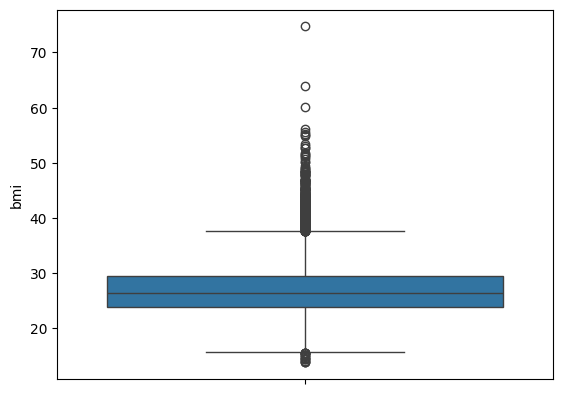

In [ ]:
numeric = ['age','chol','crp','trigl','cyst_c','hdl','thb','a1c','bmi','maxgrip']
df_imp[numeric].describe()
#from scipy import stats
#df_numeric_std = df_imp[['crp','trigl','bmi','maxgrip']].apply(stats.zscore)

#sns.boxplot(data=df_numeric_std)
#plt.title('std', fontweight='bold')
#plt.xticks(rotation=45, ha='right')
#plt.tight_layout()
#plt.show()

In [50]:
print((df_imp['crp'] < 0).sum()) #impossible
print((df_imp['trigl'] > 2000).sum()) #rare
print((df_imp['bmi'] > 50).sum())

print(df_imp[['crp']].quantile([0.0025]))

33
8
20
             crp
0.0025  0.388857


In [54]:
from scipy.stats.mstats import winsorize
df_win = df_imp.copy()
crp_win = winsorize(df_imp['crp'], limits=[0.0025, 0])
df_win['crp'] = crp_win

In [53]:
df_final = df_win.copy()
df_final = df_final.reset_index(drop=True)
df_final.to_csv('df_final.csv')

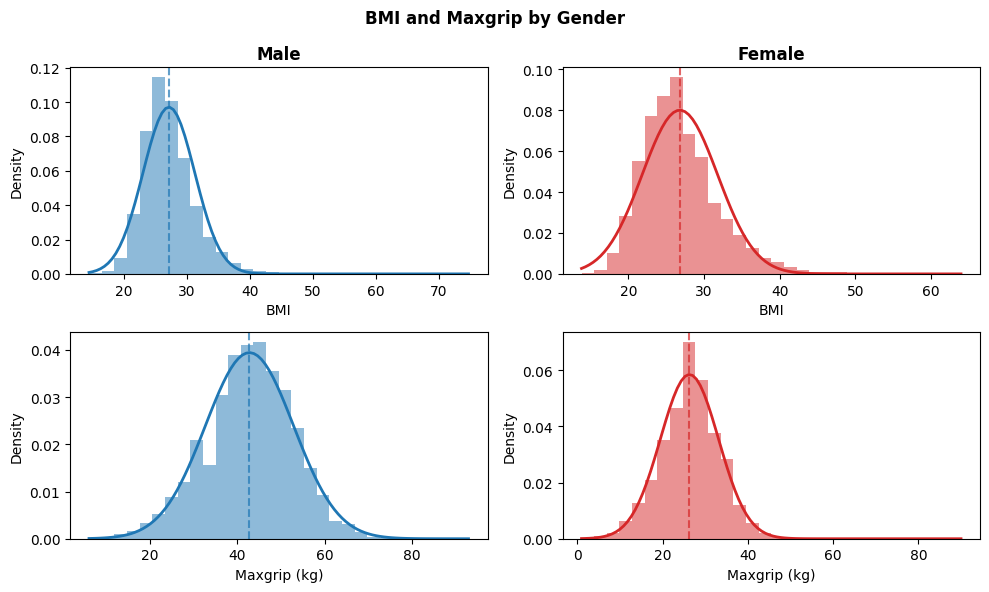

In [55]:
from scipy.stats import norm
bmi_m = df_final[df_final["gender"] == 1]["bmi"]
bmi_f = df_final[df_final["gender"] == 0]["bmi"]
mg_m = df_final[df_final["gender"] == 1]["maxgrip"]
mg_f = df_final[df_final["gender"] == 0]["maxgrip"]

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
fig.suptitle('BMI and Maxgrip by Gender', fontsize=12, fontweight='bold')

# colors
blue = '#1f77b4'
red = '#d62728'

# ----- BMI_M -----
bmi_avg_m = np.mean(bmi_m)
bmi_std_m = np.std(bmi_m, ddof=1)

axes[0,0].hist(bmi_m, bins=30, density=True, alpha=0.5, color=blue)
x_m = np.linspace(min(bmi_m), max(bmi_m), 100)
axes[0,0].plot(x_m, norm.pdf(x_m, bmi_avg_m, bmi_std_m), color=blue, linewidth=2)
axes[0,0].set_title("Male", fontweight='bold')
axes[0,0].set_xlabel("BMI")
axes[0,0].set_ylabel("Density")
axes[0,0].axvline(bmi_avg_m, color=blue, linestyle='--', alpha=0.7)

# ----- BMI_F -----
bmi_avg_f = np.mean(bmi_f)
bmi_std_f = np.std(bmi_f, ddof=1)

axes[0,1].hist(bmi_f, bins=30, density=True, alpha=0.5, color=red)
x_f = np.linspace(min(bmi_f), max(bmi_f), 100)
axes[0,1].plot(x_f, norm.pdf(x_f, bmi_avg_f, bmi_std_f), color=red, linewidth=2)
axes[0,1].set_title("Female",fontweight='bold')
axes[0,1].set_xlabel("BMI")
axes[0,1].set_ylabel("Density")
axes[0,1].axvline(bmi_avg_f, color=red, linestyle='--', alpha=0.7)

# ----- GRIP_M -----
mg_avg_m = np.mean(mg_m)
mg_std_m = np.std(mg_m, ddof=1)

axes[1,0].hist(mg_m, bins=30, density=True, alpha=0.5, color=blue)
x_mg = np.linspace(min(mg_m), max(mg_m), 100)
axes[1,0].plot(x_mg, norm.pdf(x_mg, mg_avg_m, mg_std_m), color=blue, linewidth=2)
axes[1,0].set_xlabel("Maxgrip (kg)")
axes[1,0].set_ylabel("Density")
axes[1,0].axvline(mg_avg_m, color=blue, linestyle='--', alpha=0.7)

# ----- GRIP_F -----
mg_avg_f = np.mean(mg_f)
mg_std_f = np.std(mg_f, ddof=1)

axes[1,1].hist(mg_f, bins=30, density=True, alpha=0.5, color=red)
x_fg = np.linspace(min(mg_f), max(mg_f), 100)
axes[1,1].plot(x_fg, norm.pdf(x_fg, mg_avg_f, mg_std_f), color=red, linewidth=2)
axes[1,1].set_xlabel("Maxgrip (kg)")
axes[1,1].set_ylabel("Density")
axes[1,1].axvline(mg_avg_f, color=red, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('distribuzione_bmi_grip.pdf',
            bbox_inches='tight',
            dpi=300,
            format='pdf',
            facecolor='white',
            edgecolor='none')
plt.show()

